In [1]:
import pandas as pd
import numpy as np
import joblib
import mlflow
import mlflow.sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import yaml
import os
import logging
from contextlib import nullcontext
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger()

mlflow_tracking_uri = 'http://localhost:5555'  # Optional: e.g., 'http://localhost:5555'

In [2]:
# Load dataset
# Ejecutar el siguiente comando para generar el archivo: featured_house_data.csv
# python src/features/engineer.py   --input data/processed/cleaned_house_data.csv   --output data/processed/featured_house_data.csv   --preprocessor models/trained/preprocessor.pkl
data_path = '../data/processed/featured_house_data.csv'  # Update path if needed
data = pd.read_csv(data_path)
X = data.drop('price', axis=1)
y = data['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
import pandas as pd

# 1. Cargar los datos preprocesados
df = pd.read_csv("../data/processed/featured_house_data.csv")
print(f"Dataset original shape: {df.shape}")

# 2. Separar usando el holdout fijo de la columna 'split'
train = df[df['split'] == 'train']
test = df[df['split'] == 'test']

# 3. Definir target y features (OJO: excluyendo explícitamente 'split')
target = 'price'
features = [col for col in df.columns if col not in (target, 'split')]

# 4. Crear los conjuntos finales X e y
X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print(f"X_train shape (solo numéricos): {X_train.shape}")
print(f"X_test shape (solo numéricos): {X_test.shape}")

Dataset original shape: (77, 17)
X_train shape (solo numéricos): (61, 15)
X_test shape (solo numéricos): (16, 15)


In [5]:
# Optional MLflow setup
# mlflow blocks reusing a name that belongs to a soft-deleted experiment, so
# we restore it first; if restore isn't possible we fall back to a new name.
experiment_name = "House Price Prediction Experiment"

if mlflow_tracking_uri:
    mlflow.set_tracking_uri(mlflow_tracking_uri)
    client = mlflow.tracking.MlflowClient()
    experiment = client.get_experiment_by_name(experiment_name)

    if experiment is None:
        client.create_experiment(experiment_name)
        logger.info(f"Created new MLflow experiment: {experiment_name}")
    elif experiment.lifecycle_stage == "deleted":
        try:
            client.restore_experiment(experiment.experiment_id)
            logger.warning(f"Restored soft-deleted experiment: {experiment_name}")
        except Exception:
            experiment_name = f"{experiment_name} (recreated)"
            client.create_experiment(experiment_name)
            logger.warning(
                f"Could not restore deleted experiment; created '{experiment_name}' instead."
            )

    mlflow.set_experiment(experiment_name)


INFO:root:Created new MLflow experiment: House Price Prediction Experiment


In [6]:
# Define models and hyperparameter grids
models = {
    'LinearRegression': LinearRegression(),
    'RandomForest': RandomForestRegressor(),
    'GradientBoosting': GradientBoostingRegressor(),
    'HistGradientBoosting': HistGradientBoostingRegressor()
}

model_grids = {
    'LinearRegression': {},
    'RandomForest': {
        'n_estimators': [50, 100, 150, 200, 300],
        'max_depth': [None, 5, 10, 15, 20, 25],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },
    
    'GradientBoosting': {
        'n_estimators': [50, 100, 150, 200, 300],
        'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
        'max_depth': [3, 5, 7, 10],
        'subsample': [0.8, 0.9, 1.0]
    },
    
    'HistGradientBoosting': {
        'max_iter': [50, 100, 150, 200, 300],
        'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
        'max_depth': [3, 5, 7, 10, None],
        'l2_regularization': [0.0, 0.1, 0.5, 1.0]
    }
}


In [7]:
def evaluate_model_with_gridsearch(name, model, grid, X_train, y_train, X_test, y_test):
    if grid:
        clf = GridSearchCV(model, grid, cv=3, scoring='r2', n_jobs=-1)
        clf.fit(X_train, y_train)
        best_model = clf.best_estimator_
        best_params = clf.best_params_
    else:
        model.fit(X_train, y_train)
        best_model = model
        best_params = model.get_params()

    y_pred = best_model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return {
        'mae': mae,
        'mse': mse,
        'rmse': rmse,
        'r2': r2,
        'model': best_model,
        'params': best_params
    }

print("MLflow tracking URI:", mlflow_tracking_uri)


MLflow tracking URI: http://localhost:5555


In [8]:
results = {}

with mlflow.start_run(run_name="model_comparison") if mlflow_tracking_uri else nullcontext():
    for name, model in models.items():
        logger.info(f"Training {name}...")
        with mlflow.start_run(run_name=name, nested=True) if mlflow_tracking_uri else nullcontext():
            evaluation = evaluate_model_with_gridsearch(name, model, model_grids[name], X_train, y_train, X_test, y_test)
            results[name] = evaluation

            if mlflow_tracking_uri:
                mlflow.log_params(evaluation['params'])
                mlflow.log_metrics({
                    'mae': evaluation['mae'],
                    'mse': evaluation['mse'],
                    'rmse': evaluation['rmse'],
                    'r2': evaluation['r2']
                })
                mlflow.sklearn.log_model(evaluation['model'], artifact_path=name.lower().replace(" ", "_"))
            
            print(f"{name} R2: {evaluation['r2']:.4f}, RMSE: {evaluation['rmse']:.2f}")


INFO:root:Training LinearRegression...
2026/11/06 22:00:06 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
INFO:root:Training RandomForest...


LinearRegression R2: 0.9617, RMSE: 42258.07
🏃 View run LinearRegression at: http://localhost:5555/#/experiments/3/runs/7e8c8d75ba06431db6786c57605b216d
🧪 View experiment at: http://localhost:5555/#/experiments/3


2026/11/06 22:00:35 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
INFO:root:Training GradientBoosting...


RandomForest R2: 0.9718, RMSE: 36247.79
🏃 View run RandomForest at: http://localhost:5555/#/experiments/3/runs/808152a97fdb430d9c032391a87b2199
🧪 View experiment at: http://localhost:5555/#/experiments/3


2026/11/06 22:01:00 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


GradientBoosting R2: 0.9636, RMSE: 41189.92


INFO:root:Training HistGradientBoosting...


🏃 View run GradientBoosting at: http://localhost:5555/#/experiments/3/runs/124078e0041140d890449b88d0cdff22
🧪 View experiment at: http://localhost:5555/#/experiments/3


2026/11/06 22:01:36 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


HistGradientBoosting R2: 0.8176, RMSE: 92167.41
🏃 View run HistGradientBoosting at: http://localhost:5555/#/experiments/3/runs/97f1409417ed4c7a9af4550aeced03b5
🧪 View experiment at: http://localhost:5555/#/experiments/3
🏃 View run model_comparison at: http://localhost:5555/#/experiments/3/runs/b738949b7d5a42d7bdd4ee5905923e3b
🧪 View experiment at: http://localhost:5555/#/experiments/3


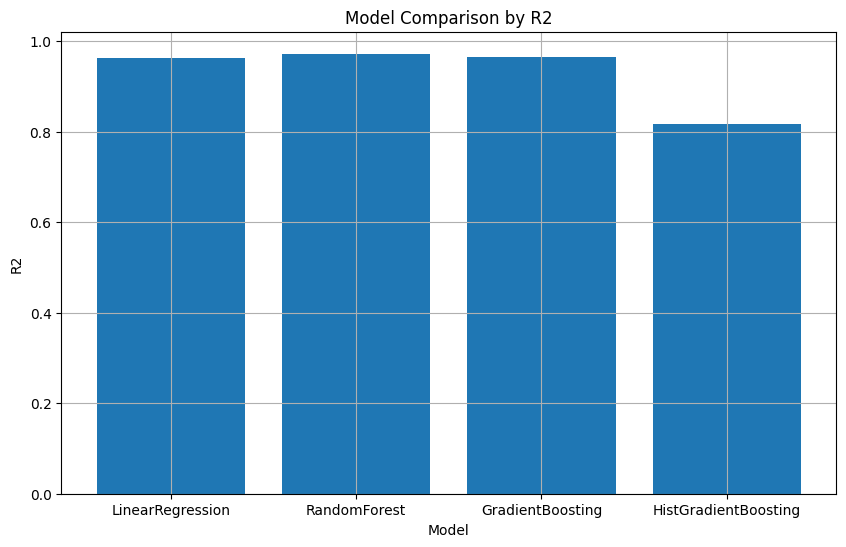

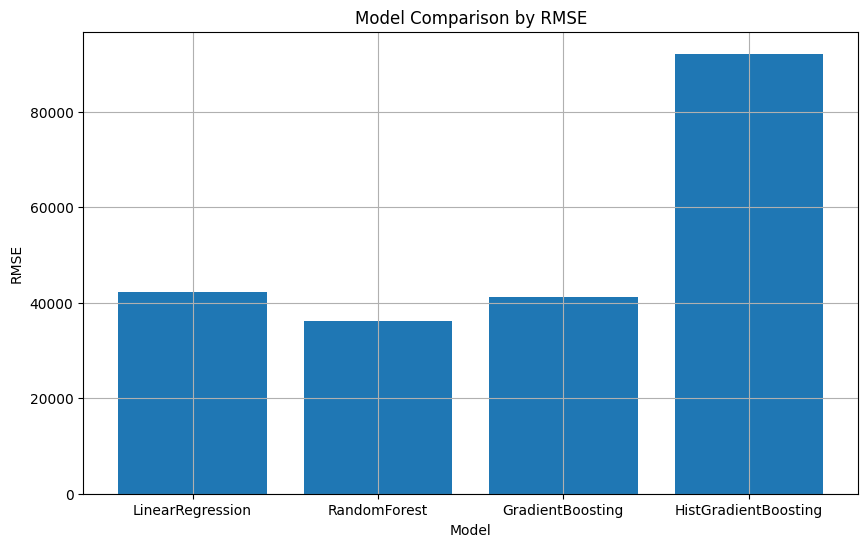

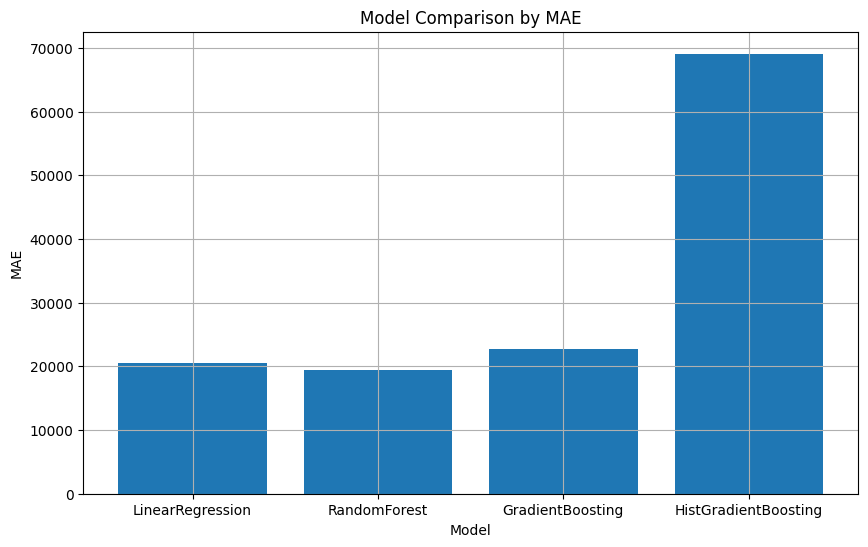

In [9]:
def plot_model_metrics(results, metric='r2'):
    names = list(results.keys())
    values = [results[name][metric] for name in names]

    plt.figure(figsize=(10, 6))
    plt.bar(names, values)
    plt.title(f'Model Comparison by {metric.upper()}')
    plt.xlabel('Model')
    plt.ylabel(metric.upper())
    plt.grid(True)
    plt.show()

# Example usage:
plot_model_metrics(results, metric='r2')
plot_model_metrics(results, metric='rmse')
plot_model_metrics(results, metric='mae')



In [10]:
import yaml

# Save model config with selected features 
# Display information about the best model
best_model_name = max(results, key=lambda x: results[x]['r2'])
best_model = results[best_model_name]['model']
best_params = best_model.get_params()
best_r2 = float(results[best_model_name]['r2'])
best_mae = float(results[best_model_name]['mae'])
best_rmse = float(results[best_model_name]['rmse'])

print(f"🏆 Best Model: {best_model_name}")
print(f"   R² Score: {best_r2:.4f}")
print(f"   MAE: {best_mae:.2f}")
print(f"   RMSE: {best_rmse:.2f}")

model_config = {
    'model': {
        'name': 'house_price_model',
        'best_model': best_model_name,
        'parameters': best_params,
        'r2_score': best_r2,
        'mae': best_mae,
        'target_variable': 'price',
        'feature_sets': selected_features_dict
    }
}

config_path = '../configs/model_config.yaml'
os.makedirs(os.path.dirname(config_path), exist_ok=True)
with open(config_path, 'w') as f:
    yaml.dump(model_config, f)

print(f"Saved model config to {config_path}")


🏆 Best Model: RandomForest
   R² Score: 0.9718
   MAE: 19412.81
   RMSE: 36247.79


NameError: name 'selected_features_dict' is not defined